In [1]:
import torch
import torch.nn as nn
import torch.optim as optim

import numpy as np

from torchvision import datasets, transforms
from torchvision.models import resnet18, ResNet18_Weights

from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split

from tqdm import tqdm
import copy

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


### 1. Pretraîtement des données

In [2]:
cnn_mean, cnn_std = [0.5], [0.5]

train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(cnn_mean, cnn_std),
])

val_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(cnn_mean, cnn_std),
])

test_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(cnn_mean, cnn_std),
])

# Load the same training directory with different transforms
train_aug = datasets.ImageFolder(
    "../dataset/Training",
    transform=train_transform
)

full_train_eval = datasets.ImageFolder(
    "../dataset/Training",
    transform=val_transform
)

test_dataset = datasets.ImageFolder(
    "../dataset/Testing",
    transform=test_transform
)

# avoir les  label
targets = train_aug.targets
indices = list(range(len(targets)))

# separer en deux groupes train/val
train_idx, val_idx = train_test_split(
    indices,
    test_size=0.2,
    stratify=targets,
    random_state=42
)


train_dataset = Subset(train_aug, train_idx)
val_dataset = Subset(full_train_eval, val_idx)


train_loader = DataLoader(
    train_dataset, batch_size=32,
    shuffle=True, num_workers=4
)

val_loader = DataLoader(
    val_dataset, batch_size=32,
    shuffle=False, num_workers=4
)


test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=4,
    pin_memory=True
)

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_loader))

Training: 4480
Validation: 1120
Test: 50


### 2. Modèle CNN

environ 390 000 paramètres

In [19]:
# Hyperparametres

NUM_CLASSES = 4
LEARNING_RATE = 1e-4
EPOCHS = 30

images, labels = next(iter(train_loader))

print("Images:", images.shape)
print("Labels:", labels.shape)
print("Classes:", train_aug.classes)

Images: torch.Size([32, 1, 224, 224])
Labels: torch.Size([32])
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [20]:
def conv_block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2),
    )

class SmallCNN(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(1, 16), conv_block(16, 32), conv_block(32, 64),
            conv_block(64, 128), conv_block(128, 256),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(256, num_classes))

    def forward(self, x):
        x = self.pool(self.features(x)).flatten(1)
        return self.classifier(x)

model = SmallCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

In [21]:
x = torch.zeros(2, 1, 224, 224).to(device)
print(model(x).shape)
print(model.features(x).shape)
print(sum(p.numel() for p in model.parameters()))

torch.Size([2, 4])
torch.Size([2, 256, 7, 7])
393844


In [22]:
def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(loader, leave=False):

        images = images.to(device)
        labels = labels.to(device)
        
        optimizer.zero_grad()
    
        outputs = model(images)

        loss = criterion(outputs, labels)
        
        loss.backward()

        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc

In [23]:
def validate(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc

### 3. Entrainement

In [24]:
best_val_acc = 0.0

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

for epoch in range(EPOCHS):

    print(f"\nEpoch [{epoch+1}/{EPOCHS}]")

    # Training
    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    # Validation
    val_loss, val_acc = validate(
        model, val_loader, criterion, device
    )

    # historique
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}%")
    print(f"Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.2f}%")

    if val_acc > best_val_acc:

        best_val_acc = val_acc

        torch.save(
            model.state_dict(),
            "../models/best_cnn_scratch.pth"
        )

        print("Enregistrement du meilleur model")

print("Entraînement complete!")
print(f"Validation Accuracy: {best_val_acc:.2f}%")


Epoch [1/30]


Train Loss: 0.8646 | Train Acc: 65.36%
Val Loss:   0.6375 | Val Acc:   77.59%
Enregistrement du meilleur model

Epoch [2/30]


Train Loss: 0.6211 | Train Acc: 76.79%
Val Loss:   0.5192 | Val Acc:   82.68%
Enregistrement du meilleur model

Epoch [3/30]


Train Loss: 0.5420 | Train Acc: 79.73%
Val Loss:   0.4716 | Val Acc:   84.02%
Enregistrement du meilleur model

Epoch [4/30]


Train Loss: 0.4943 | Train Acc: 81.88%
Val Loss:   0.5029 | Val Acc:   77.59%

Epoch [5/30]


Train Loss: 0.4686 | Train Acc: 82.75%
Val Loss:   0.4828 | Val Acc:   80.71%

Epoch [6/30]


... (21 outputs left out)

Train Loss: 0.2186 | Train Acc: 92.43%
Val Loss:   0.2246 | Val Acc:   92.23%
Enregistrement du meilleur model

Epoch [28/30]


Train Loss: 0.2257 | Train Acc: 91.90%
Val Loss:   0.2545 | Val Acc:   91.43%

Epoch [29/30]


Train Loss: 0.2241 | Train Acc: 92.14%
Val Loss:   0.2486 | Val Acc:   91.52%

Epoch [30/30]


Train Loss: 0.2144 | Train Acc: 92.48%
Val Loss:   0.3350 | Val Acc:   87.86%
Entraînement complete!
Validation Accuracy: 92.23%


In [25]:
model.load_state_dict(
    torch.load(
        "../models/best_cnn_scratch.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

SmallCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0

### 4. Evaluation du model

In [26]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

# accuracy
test_acc = accuracy_score(all_labels, all_preds)

print(f"Test Accuracy: {test_acc * 100:.2f}%")

print(classification_report(
    all_labels,
    all_preds,
    target_names=train_aug.classes,
    digits=4
))

Test Accuracy: 86.75%
              precision    recall  f1-score   support

      glioma     0.9586    0.6950    0.8058       400
  meningioma     0.8214    0.8050    0.8131       400
     notumor     0.8372    0.9900    0.9072       400
   pituitary     0.8809    0.9800    0.9278       400

    accuracy                         0.8675      1600
   macro avg     0.8745    0.8675    0.8635      1600
weighted avg     0.8745    0.8675    0.8635      1600



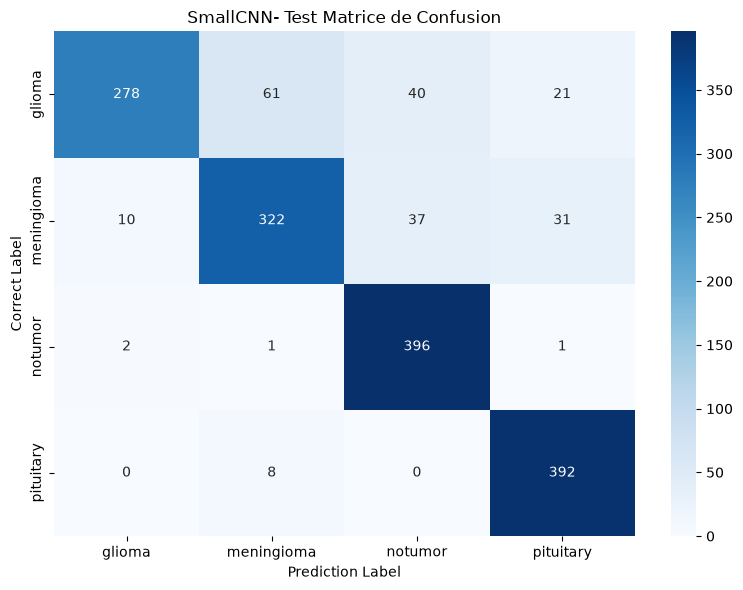

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=train_aug.classes,
    yticklabels=train_aug.classes
)

plt.xlabel("Prediction Label")
plt.ylabel("Correct Label")
plt.title("SmallCNN- Test Matrice de Confusion")

plt.tight_layout()
plt.show()

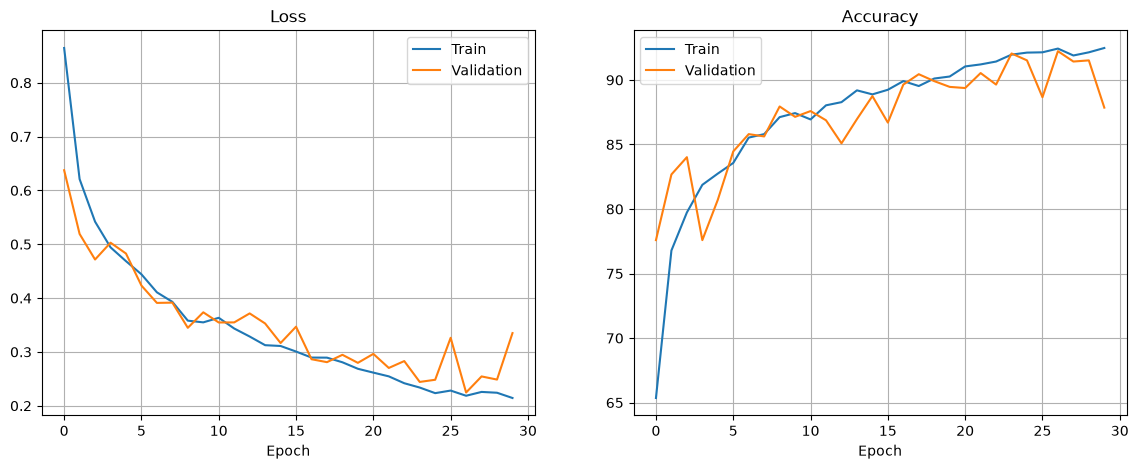

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history["train_loss"], label="Train")
axes[0].plot(history["val_loss"], label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid()

axes[1].plot(history["train_acc"], label="Train")
axes[1].plot(history["val_acc"], label="Validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid()

plt.show()

### 5. GradCAM

In [29]:
import torch.nn.functional as F

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None

        # Récupère les activations de la couche cible
        self.handle = target_layer.register_forward_hook(
            self.save_activation
        )

    def save_activation(self, module, input, output):
        self.activations = output

    def generate(self, input_tensor, class_idx=None):
        self.model.eval()
        self.model.zero_grad()

        # Forward pass
        output = self.model(input_tensor)

        # Classe à expliquer : prédite par défaut
        if class_idx is None:
            class_idx = output.argmax(dim=1).item()

        score = output[:, class_idx]

        # Gradient du score par rapport aux activations
        gradients = torch.autograd.grad(
            outputs=score,
            inputs=self.activations
        )[0]

        # Moyenne spatiale des gradients par canal
        weights = gradients.mean(dim=(2, 3), keepdim=True)

        # Combinaison pondérée des cartes d'activation
        cam = (weights * self.activations).sum(dim=1)
        cam = F.relu(cam)

        # Normalisation entre 0 et 1
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)

        # Redimensionnement à la taille de l'image
        cam = F.interpolate(
            cam.unsqueeze(1),
            size=input_tensor.shape[2:],
            mode="bilinear",
            align_corners=False
        )

        return cam.squeeze().detach().cpu().numpy(), output

    def remove_hook(self):
        self.handle.remove()

In [30]:
gradcam = GradCAM(
    model=model,
    target_layer=model.features[-1]
)

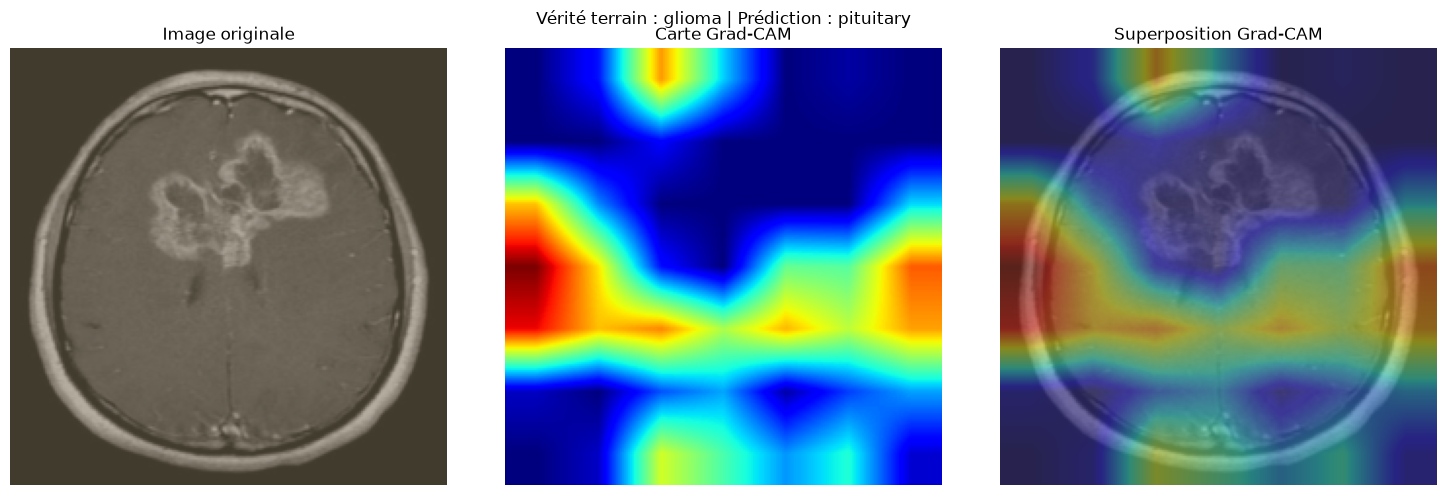

In [31]:
import numpy as np
import matplotlib.pyplot as plt

# Choisir une image du jeu de test
idx = 0

image_tensor, true_label = test_dataset[idx]

# Ajouter la dimension batch
input_tensor = image_tensor.unsqueeze(0).to(device)

# Générer Grad-CAM
cam, output = gradcam.generate(input_tensor)

# Récupérer la prédiction
predicted_label = output.argmax(dim=1).item()

# Dénormaliser l'image pour l'affichage
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

original_image = image_tensor.cpu() * std + mean
original_image = original_image.permute(1, 2, 0).numpy()
original_image = np.clip(original_image, 0, 1)

# Affichage
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(original_image)
axes[0].set_title("Image originale")

axes[1].imshow(cam, cmap="jet")
axes[1].set_title("Carte Grad-CAM")

axes[2].imshow(original_image)
axes[2].imshow(cam, cmap="jet", alpha=0.4)
axes[2].set_title("Superposition Grad-CAM")

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"Vérité terrain : {test_dataset.classes[true_label]} | "
    f"Prédiction : {test_dataset.classes[predicted_label]}"
)

plt.tight_layout()
plt.show()

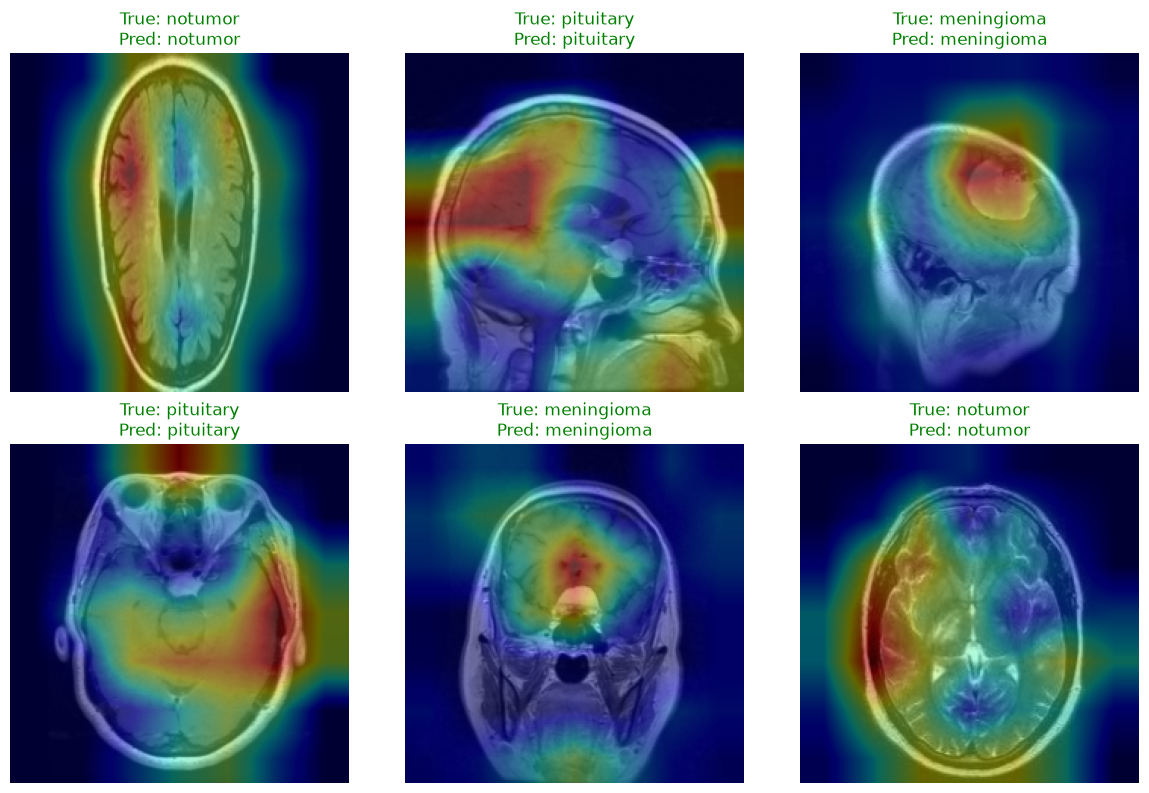

In [32]:
import random

indices = random.sample(
    range(len(test_dataset)),
    6
)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, idx in zip(axes.flat, indices):

    image_tensor, true_label = test_dataset[idx]
    input_tensor = image_tensor.unsqueeze(0).to(device)

    cam, output = gradcam.generate(input_tensor)
    predicted_label = output.argmax(dim=1).item()

    # Dénormalisation
    img = image_tensor * 0.5 + 0.5
    img = img.permute(1, 2, 0).numpy()
    img = np.clip(img, 0, 1)

    ax.imshow(img.squeeze(), cmap="gray")
    ax.imshow(cam, cmap="jet", alpha=0.4)

    correct = predicted_label == true_label

    ax.set_title(
        f"True: {test_dataset.classes[true_label]}\n"
        f"Pred: {test_dataset.classes[predicted_label]}",
        color="green" if correct else "red"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

### 6. Logits & Calibration (ECE, diagramme de fiabilité, temperature scaling)

In [ ]:
@torch.no_grad()
def get_logits(model, loader):
    model.eval()
    outs, ys = [], []
    for x, y in loader:
        outs.append(model(x.to(device)).cpu())
        ys.append(y)
    return torch.cat(outs).numpy(), torch.cat(ys).numpy()

val_logits, val_y = get_logits(model, val_loader)
test_logits, test_y = get_logits(model, test_loader)
np.savez("../results/logits_cnn.npz", val_logits=val_logits, val_y=val_y,
         test_logits=test_logits, test_y=test_y)

In [ ]:
d = np.load("../results/logits_cnn.npz")
print({k: d[k].shape for k in d.files})
print("acc test :", (d["test_logits"].argmax(1) == d["test_y"]).mean())